# Données météo pour anticiper les crises de supply chain

**Projet 6 – ESME Sudria.** Ce notebook extrait des données météo gratuites (Open-Meteo) sur des sites sensibles de la chaîne d'approvisionnement, puis cherche **quelles variables sont vraiment utiles** pour anticiper une perturbation.

**Démarche**

1. Extraire 15 ans d'historique météo et de débit des rivières pour une dizaine de sites.
2. Construire des indicateurs de risque (pluie cumulée, rafales, gel, crue, basses eaux…).
3. Fixer des seuils **propres à chaque site**, calculés sur 2010-2020 uniquement.
4. Vérifier sur **quatre perturbations réelles** si les indicateurs auraient alerté, et avec combien de jours d'avance.
5. Mesurer le **bruit** : combien d'alertes chaque indicateur déclenche par an.
6. Tester l'anticipation avec les **prévisions archivées** (ce que les modèles prévoyaient avant Helene).
7. Appliquer le tout aux **prévisions des 16 prochains jours** (mode live) et exporter les résultats.

**Pour l'exécuter** : Python 3.10+, `pip install pandas numpy requests matplotlib`. Aucune clé d'API n'est nécessaire. Les réponses de l'API sont gardées en cache dans `data/cache/`, donc une deuxième exécution ne refait aucune requête.

> **Licence.** Open-Meteo est gratuit pour un usage **non commercial** (projet étudiant). Un usage commercial demandera un abonnement : à prévoir dans le business plan.

## 0. Les sources de données utilisées

| API Open-Meteo | Ce qu'elle donne | Période | Usage dans le projet |
| --- | --- | --- | --- |
| **Historical Weather** (`archive-api`) | Réanalyse ERA5 : la météo « observée », reconstituée sur une grille d'environ 25 km | 1940 → il y a ~5 jours | Calibrer les seuils, rejouer les crises |
| **Flood** (`flood-api`) | Débit des rivières (modèle GloFAS), en m³/s | 1984 → + prévision | Crues et basses eaux |
| **Previous Runs** (`previous-runs-api`) | Ce que les modèles **prévoyaient** 1 à 7 jours avant | Depuis janv. 2024 (la plupart des modèles) | Mesurer l'anticipation réelle, sans tricher |
| **Forecast** (`api`) | Prévisions jusqu'à 16 jours | Aujourd'hui → J+16 | Mode live |

**Point clé pour le replay** : la réanalyse ERA5 montre ce qui s'est *passé*, pas ce qu'on *savait* à l'époque. Pour mesurer une vraie avance, il faut les prévisions archivées (section 6).

## 1. Configuration

In [3]:
import hashlib
import json
import time
from datetime import date, timedelta
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "cache"
OUT_DIR = Path("sorties")
for dossier in (CACHE_DIR, OUT_DIR):
    dossier.mkdir(parents=True, exist_ok=True)

DEBUT = "2010-01-01"
FIN = (date.today() - timedelta(days=7)).isoformat()  # ERA5 est publié avec quelques jours de retard
FIN_CALIBRATION = "2020-12-31"  # les seuils ne voient que 2010-2020

# Palette des graphiques (couleurs validées daltonisme)
BLEU, ORANGE = "#2a78d6", "#eb6834"
ROUGE_CRITIQUE = "#d03b3b"
ENCRE, ENCRE_2, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2,
    "ytick.color": ENCRE_2, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9.5,
})
print(f"Période extraite : {DEBUT} → {FIN}  |  seuils calibrés jusqu'au {FIN_CALIBRATION}")

Période extraite : 2010-01-01 → 2026-10-31  |  seuils calibrés jusqu'au 2020-12-31


In [4]:
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "projet6-supply-chain-notebook"


def appel_api(url, params, pause=0.6, essais=4):
    """Requête GET JSON avec cache disque : chaque requête n'est envoyée qu'une seule fois."""
    cle = hashlib.md5((url + json.dumps(params, sort_keys=True)).encode()).hexdigest()
    fichier = CACHE_DIR / f"{cle}.json"
    if fichier.exists():
        return json.loads(fichier.read_text())
    for essai in range(essais):
        reponse = SESSION.get(url, params=params, timeout=90)
        if reponse.status_code == 429:  # trop de requêtes : on patiente puis on réessaie
            time.sleep(15 * (essai + 1))
            continue
        try:
            data = reponse.json()
        except ValueError:
            raise RuntimeError(f"Réponse illisible ({reponse.status_code}) : {reponse.text[:200]}")
        if reponse.status_code != 200 or (isinstance(data, dict) and data.get("error")):
            raison = data.get("reason", data) if isinstance(data, dict) else data
            raise RuntimeError(f"Erreur API ({reponse.status_code}) : {raison}")
        fichier.write_text(json.dumps(data))
        time.sleep(pause)
        return data
    raise RuntimeError("Limite de requêtes atteinte : réessayer dans quelques minutes.")


def vers_dataframe(data, bloc="daily"):
    df = pd.DataFrame(data[bloc])
    df["time"] = pd.to_datetime(df["time"])
    return df.rename(columns={"time": "date"})

## 2. Les sites surveillés

Dix sites, choisis pour couvrir **plusieurs secteurs et plusieurs types de risque**. Les coordonnées sont approximatives (centre de la zone), ce qui suffit à l'échelle d'une grille météo de 10 à 25 km.

Pour le projet, cette liste sera remplacée par les sites du graphe fournisseurs.

In [5]:
SITES = pd.DataFrame([
    ("Spruce Pine",   "États-Unis",  35.915,  -82.065, "Mines de quartz haute pureté",        "pluie, crue"),
    ("Austin",        "États-Unis",  30.267,  -97.743, "Usines de semi-conducteurs",          "gel, chaleur"),
    ("Savannah",      "États-Unis",  32.080,  -81.090, "Port à conteneurs",                   "ouragan, vent"),
    ("Kaub (Rhin)",   "Allemagne",   50.085,    7.765, "Goulet de la navigation sur le Rhin", "basses eaux"),
    ("Rotterdam",     "Pays-Bas",    51.950,    4.140, "Premier port européen",               "tempête"),
    ("Hambourg",      "Allemagne",   53.546,    9.966, "Port et usine de semi-conducteurs",   "tempête, crue"),
    ("Ayutthaya",     "Thaïlande",   14.355,  100.568, "Zones industrielles (électronique, auto)", "inondation"),
    ("Kaohsiung",     "Taïwan",      22.610,  120.300, "Port et fonderies",                   "typhon"),
    ("Shanghai",      "Chine",       30.620,  122.060, "Port de Yangshan",                    "typhon"),
    ("Dongguan",      "Chine",       23.020,  113.750, "Usines d'électronique",               "pluie, typhon"),
], columns=["site", "pays", "lat", "lon", "role", "risque_attendu"])
SITES

,site,pays,lat,lon,role,risque_attendu
0,Spruce Pine,États-Unis,35.915,-82.065,Mines de quartz haute pureté,"pluie, crue"
1,Austin,États-Unis,30.267,-97.743,Usines de semi-conducteurs,"gel, chaleur"
2,Savannah,États-Unis,32.080,-81.090,Port à conteneurs,"ouragan, vent"
3,Kaub (Rhin),Allemagne,50.085,7.765,Goulet de la navigation sur le Rhin,basses eaux
4,Rotterdam,Pays-Bas,51.950,4.140,Premier port européen,tempête
5,Hambourg,Allemagne,53.546,9.966,Port et usine de semi-conducteurs,"tempête, crue"
6,Ayutthaya,Thaïlande,14.355,100.568,"Zones industrielles (électronique, auto)",inondation
7,Kaohsiung,Taïwan,22.610,120.300,Port et fonderies,typhon
8,Shanghai,Chine,30.620,122.060,Port de Yangshan,typhon
9,Dongguan,Chine,23.020,113.750,Usines d'électronique,"pluie, typhon"


## 3. Extraction

Une requête par site et par API. Variables quotidiennes demandées :

| Variable | Unité | Pourquoi |
| --- | --- | --- |
| `precipitation_sum` | mm | Crues, routes coupées, inondations |
| `precipitation_hours` | h | Pluie persistante vs averse |
| `snowfall_sum` | cm | Routes et voies ferrées bloquées |
| `temperature_2m_max` / `_min` | °C | Canicule, gel, coupures électriques |
| `wind_speed_10m_max` / `wind_gusts_10m_max` | km/h | Arrêt des ports et des grues, dégâts |
| `weather_code` | code OMM | Type de temps (orage, neige…) – exploratoire |
| `river_discharge` (Flood API) | m³/s | Crues et basses eaux des rivières |

In [6]:
URL_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
URL_FLOOD = "https://flood-api.open-meteo.com/v1/flood"
URL_PREVIOUS = "https://previous-runs-api.open-meteo.com/v1/forecast"
URL_FORECAST = "https://api.open-meteo.com/v1/forecast"

VARIABLES_JOUR = [
    "temperature_2m_max", "temperature_2m_min", "precipitation_sum", "precipitation_hours",
    "snowfall_sum", "wind_speed_10m_max", "wind_gusts_10m_max", "weather_code",
]


def meteo_historique(site, debut=DEBUT, fin=FIN):
    params = dict(latitude=site.lat, longitude=site.lon, start_date=debut, end_date=fin,
                  daily=",".join(VARIABLES_JOUR), timezone="auto")
    df = vers_dataframe(appel_api(URL_ARCHIVE, params))
    df.insert(0, "site", site.site)
    return df


def debit_historique(site, debut=DEBUT, fin=FIN):
    params = dict(latitude=site.lat, longitude=site.lon, start_date=debut, end_date=fin,
                  daily="river_discharge")
    df = vers_dataframe(appel_api(URL_FLOOD, params))
    df.insert(0, "site", site.site)
    return df


tables_meteo, tables_debit = [], []
for site in SITES.itertuples():
    print(f"→ {site.site:<14}", end=" ")
    tables_meteo.append(meteo_historique(site))
    try:
        tables_debit.append(debit_historique(site))
        print("météo ✓  débit ✓")
    except RuntimeError as erreur:  # certains sites n'ont pas de rivière exploitable
        print(f"météo ✓  débit ✗ ({erreur})")

meteo = pd.concat(tables_meteo, ignore_index=True)
debit = pd.concat(tables_debit, ignore_index=True) if tables_debit else pd.DataFrame(columns=["site", "date", "river_discharge"])
donnees = meteo.merge(debit, on=["site", "date"], how="left")
donnees.to_csv(OUT_DIR / "meteo_brut.csv", index=False)
print(f"\n{len(donnees):,} lignes · {donnees['site'].nunique()} sites · du {donnees['date'].min():%d/%m/%Y} au {donnees['date'].max():%d/%m/%Y}")
donnees.head()

→ Spruce Pine    météo ✓  débit ✓
→ Austin         météo ✓  débit ✓
→ Savannah       météo ✓  débit ✓
→ Kaub (Rhin)    météo ✓  débit ✓
→ Rotterdam      météo ✓  débit ✓
→ Hambourg       météo ✓  débit ✓
→ Ayutthaya      météo ✓  débit ✓
→ Kaohsiung      météo ✓  débit ✓
→ Shanghai       météo ✓  débit ✓
→ Dongguan       météo ✓  débit ✓

61,480 lignes · 10 sites · du 01/01/2010 au 31/10/2026


,site,date,temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_hours,snowfall_sum,wind_speed_10m_max,wind_gusts_10m_max,weather_code,river_discharge
0,Spruce Pine,2010-01-01,1.5,-6.6,0.2,2.0,0.42,21.3,60.8,71,4.08
1,Spruce Pine,2010-01-02,-6.6,-12.0,0.0,0.0,0.00,26.4,73.8,3,4.01
2,Spruce Pine,2010-01-03,-6.5,-13.1,0.0,0.0,0.00,21.9,66.6,1,3.97
3,Spruce Pine,2010-01-04,-5.2,-12.0,0.0,0.0,0.00,22.7,61.9,3,3.92
4,Spruce Pine,2010-01-05,-5.5,-9.9,0.0,0.0,0.00,22.2,60.5,3,3.89


## 4. Qualité et premier aperçu

Avant toute analyse : la période couverte et la part de valeurs manquantes. Le débit est souvent manquant sur les derniers mois (données consolidées avec retard) et peut ne rien donner pour un site côtier sans grande rivière.

In [7]:
colonnes_cles = ["precipitation_sum", "wind_gusts_10m_max", "temperature_2m_min", "snowfall_sum", "river_discharge"]
qualite = donnees.groupby("site").agg(
    debut=("date", "min"), fin=("date", "max"), jours=("date", "size"),
    **{f"manquant_{c}": (c, lambda s: round(100 * s.isna().mean(), 1)) for c in colonnes_cles},
)
qualite.loc[SITES["site"]]

,debut,fin,jours,manquant_precipitation_sum,manquant_wind_gusts_10m_max,manquant_temperature_2m_min,manquant_snowfall_sum,manquant_river_discharge
site,,,,,,,,
Spruce Pine,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Austin,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Savannah,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Kaub (Rhin),2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Rotterdam,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Hambourg,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Ayutthaya,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Kaohsiung,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,0.0
Shanghai,2010-01-01,2026-10-31,6148,0.0,0.0,0.0,0.0,100.0


In [8]:
# Profil climatique de chaque site : de quoi comprendre pourquoi un seuil unique serait absurde
profil = donnees.assign(annee=donnees["date"].dt.year).groupby("site").agg(
    pluie_annuelle_mm=("precipitation_sum", lambda s: s.sum() / donnees["date"].dt.year.nunique()),
    pluie_jour_record_mm=("precipitation_sum", "max"),
    rafale_record_kmh=("wind_gusts_10m_max", "max"),
    temp_min_record=("temperature_2m_min", "min"),
    temp_max_record=("temperature_2m_max", "max"),
    neige_jours_par_an=("snowfall_sum", lambda s: (s >= 1).sum() / donnees["date"].dt.year.nunique()),
    debit_median_m3s=("river_discharge", "median"),
).round(1)
profil.loc[SITES["site"]]

,pluie_annuelle_mm,pluie_jour_record_mm,rafale_record_kmh,temp_min_record,temp_max_record,neige_jours_par_an,debit_median_m3s
site,,,,,,,
Spruce Pine,1383.2,136.2,132.1,-20.3,35.1,9.6,5.44
Austin,1071.0,128.0,96.5,-15.3,42.5,0.5,22.12
Savannah,1224.8,153.4,126.0,-7.6,38.8,0.2,227.56
Kaub (Rhin),698.0,37.5,121.7,-17.7,39.3,2.2,0.16
Rotterdam,879.4,52.6,133.6,-11.1,38.3,5.0,0.22
Hambourg,777.6,42.2,122.4,-18.6,39.3,9.1,1.35
Ayutthaya,1518.8,159.8,74.2,12.9,42.2,0.0,0.25
Kaohsiung,1937.9,343.6,139.7,7.4,35.2,0.0,1.0
Shanghai,1289.0,180.4,125.6,-5.0,33.5,0.2,NaN


**À lire** : 100 mm de pluie en une journée sont banals à Kaohsiung pendant la saison des typhons et exceptionnels à Rotterdam. Les seuils doivent donc être **relatifs à chaque site**, pas absolus.

## 5. Indicateurs de risque et seuils propres à chaque site

Certaines perturbations viennent d'un **pic** (une rafale), d'autres d'une **accumulation** (trois mois de pluie en Thaïlande, plusieurs semaines de sécheresse sur le Rhin). On construit donc des indicateurs sur plusieurs durées.

**Règle d'alerte** : un indicateur alerte quand il dépasse son quantile 99 % (ou passe sous son quantile 1 % pour le gel et les basses eaux), **calculé sur 2010-2020 uniquement**. Les crises de 2021 à 2024 ne servent donc jamais à fixer les seuils : pas de biais rétrospectif.

Les quantiles et le plancher de neige sont des **choix de départ, à ajuster** selon le bruit observé plus bas.

In [9]:
def ajouter_indicateurs(df):
    df = df.sort_values(["site", "date"]).copy()
    g = df.groupby("site", group_keys=False)
    df["pluie_3j"] = g["precipitation_sum"].transform(lambda s: s.rolling(3, min_periods=3).sum())
    df["pluie_90j"] = g["precipitation_sum"].transform(lambda s: s.rolling(90, min_periods=80).sum())
    df["temp_min_3j"] = g["temperature_2m_min"].transform(lambda s: s.rolling(3, min_periods=3).min())
    df["debit_7j"] = g["river_discharge"].transform(lambda s: s.rolling(7, min_periods=5).mean())
    return df


INDICATEURS = pd.DataFrame([
    # id,             colonne,              sens,   quantile, unité,  risque pour la supply chain
    ("pluie_3j",      "pluie_3j",           "haut", 0.99, "mm",   "Crue éclair, routes et voies ferrées coupées"),
    ("pluie_90j",     "pluie_90j",          "haut", 0.99, "mm",   "Inondation lente, zones industrielles noyées"),
    ("rafales",       "wind_gusts_10m_max", "haut", 0.99, "km/h", "Arrêt des ports et des grues, dégâts"),
    ("neige",         "snowfall_sum",       "haut", 0.99, "cm",   "Routes et rail bloqués"),
    ("chaleur",       "temperature_2m_max", "haut", 0.99, "°C",   "Canicule : coupures électriques, rendement"),
    ("gel",           "temp_min_3j",        "bas",  0.01, "°C",   "Gel : coupures électriques, installations gelées"),
    ("crue",          "debit_7j",           "haut", 0.99, "m³/s", "Crue de rivière"),
    ("basses_eaux",   "debit_7j",           "bas",  0.01, "m³/s", "Navigation fluviale limitée"),
], columns=["indicateur", "colonne", "sens", "q", "unite", "risque"])
PLANCHER = {"neige": 1.0}  # en dessous d'1 cm, la neige ne bloque rien

donnees = ajouter_indicateurs(donnees)
INDICATEURS

,indicateur,colonne,sens,q,unite,risque
0,pluie_3j,pluie_3j,haut,0.99,mm,"Crue éclair, routes et voies ferrées coupées"
1,pluie_90j,pluie_90j,haut,0.99,mm,"Inondation lente, zones industrielles noyées"
2,rafales,wind_gusts_10m_max,haut,0.99,km/h,"Arrêt des ports et des grues, dégâts"
3,neige,snowfall_sum,haut,0.99,cm,Routes et rail bloqués
4,chaleur,temperature_2m_max,haut,0.99,°C,"Canicule : coupures électriques, rendement"
5,gel,temp_min_3j,bas,0.01,°C,"Gel : coupures électriques, installations gelées"
6,crue,debit_7j,haut,0.99,m³/s,Crue de rivière
7,basses_eaux,debit_7j,bas,0.01,m³/s,Navigation fluviale limitée


In [10]:
def seuil(site, ind, exclure_annee=None, fin_calibration=FIN_CALIBRATION):
    """Seuil d'un indicateur pour un site, calculé sur la période de calibration."""
    sel = (donnees["site"] == site) & (donnees["date"] <= fin_calibration)
    if exclure_annee is not None:
        sel &= donnees["date"].dt.year != exclure_annee
    valeurs = donnees.loc[sel, ind.colonne].dropna()
    if len(valeurs) < 365:  # pas assez de données (ex. pas de rivière)
        return np.nan
    return valeurs.quantile(ind.q)


def depasse(valeurs, seuil_val, ind):
    plancher = PLANCHER.get(ind.indicateur, -np.inf)
    if ind.sens == "haut":
        return (valeurs > seuil_val) & (valeurs >= plancher)
    return valeurs < seuil_val


SEUILS = pd.DataFrame(
    [(s, ind.indicateur, seuil(s, ind)) for s in SITES["site"] for ind in INDICATEURS.itertuples()],
    columns=["site", "indicateur", "seuil"],
)
SEUIL = {(r.site, r.indicateur): r.seuil for r in SEUILS.itertuples()}
tableau_seuils = SEUILS.pivot(index="site", columns="indicateur", values="seuil").loc[SITES["site"], INDICATEURS["indicateur"]]
tableau_seuils.round(1)

indicateur,pluie_3j,pluie_90j,rafales,neige,chaleur,gel,crue,basses_eaux
site,,,,,,,,
Spruce Pine,73.9,631.7,95.7,3.8,30.7,-14.5,18.9,3.8
Austin,80.6,632.4,66.6,0.0,39.2,-3.8,304.6,9.0
Savannah,70.0,761.8,72.7,0.0,35.9,-3.3,1019.1,110.8
Kaub (Rhin),30.1,279.8,82.4,0.8,32.7,-9.5,4.9,0.0
Rotterdam,34.2,377.5,93.5,1.1,28.6,-5.7,0.9,0.1
Hambourg,32.5,348.4,80.2,2.2,30.8,-11.3,4.6,0.5
Ayutthaya,66.7,850.9,55.3,0.0,38.6,16.2,3.7,0.0
Kaohsiung,191.8,1589.5,70.1,0.0,33.0,10.9,12.6,0.6
Shanghai,94.6,764.8,76.2,0.0,30.2,0.7,NaN,NaN


In [11]:
# Drapeaux d'alerte et score de risque météo (0 à 1) pour chaque site et chaque jour
calib = donnees["date"] <= FIN_CALIBRATION
for ind in INDICATEURS.itertuples():
    drapeau = pd.Series(False, index=donnees.index)
    rang = pd.Series(np.nan, index=donnees.index)
    for site, idx in donnees.groupby("site").groups.items():
        s = SEUIL[(site, ind.indicateur)]
        if np.isnan(s):
            continue
        vals = donnees.loc[idx, ind.colonne]
        drapeau.loc[idx] = depasse(vals, s, ind).fillna(False)
        ref = np.sort(donnees.loc[idx[calib.loc[idx].to_numpy()], ind.colonne].dropna().to_numpy())
        v = vals.to_numpy()
        if ind.sens == "haut":  # part des jours de calibration strictement plus faibles
            r = np.searchsorted(ref, v, side="left") / len(ref)
            r = np.where(v < PLANCHER.get(ind.indicateur, -np.inf), 0.0, r)
        else:                   # part des jours de calibration strictement plus élevés
            r = 1 - np.searchsorted(ref, v, side="right") / len(ref)
        rang.loc[idx] = np.where(vals.isna(), np.nan, r)
    donnees[f"alerte_{ind.indicateur}"] = drapeau
    donnees[f"rang_{ind.indicateur}"] = rang

cols_rang = [f"rang_{i}" for i in INDICATEURS["indicateur"]]
cols_alerte = [f"alerte_{i}" for i in INDICATEURS["indicateur"]]
donnees["score_meteo"] = donnees[cols_rang].max(axis=1)        # 0,99 = jour parmi les 1 % les plus extrêmes du site
donnees["alerte_meteo"] = donnees[cols_alerte].any(axis=1)
donnees[["site", "date", "score_meteo", "alerte_meteo"]].tail()

,site,date,score_meteo,alerte_meteo
6143,Spruce Pine,2026-10-27,0.771051,False
6144,Spruce Pine,2026-10-28,0.852765,False
6145,Spruce Pine,2026-10-29,0.907823,False
6146,Spruce Pine,2026-10-30,0.938964,False
6147,Spruce Pine,2026-10-31,0.955406,False


## 6. Validation sur des perturbations réelles

Quatre perturbations documentées, chacune d'un type différent. Pour chacune, on regarde si l'indicateur a dépassé son seuil **avant** la date de la perturbation, et avec combien de jours d'avance.

| Cas | Site | Date de la perturbation | Ce qui s'est passé |
| --- | --- | --- | --- |
| Ouragan Helene (2024) | Spruce Pine | 26/09/2024 | Arrêt préventif des mines de quartz haute pureté |
| Tempête hivernale Uri (2021) | Austin | 16/02/2021 | Arrêt partiel de l'usine Samsung, coupures électriques |
| Basses eaux du Rhin (2022) | Kaub | 11/08/2022 | Barges qui ne desservent plus Cologne et Düsseldorf |
| Inondations en Thaïlande (2011) | Ayutthaya | 08/10/2011 | Rupture de la digue de la zone industrielle Rojana |

**Attention** : ici on lit la réanalyse, donc ce qui a été *observé*. Un dépassement avant la date de la perturbation veut dire qu'une surveillance des observations aurait alerté. La vraie anticipation par la prévision est testée en section 7.

Pour Ayutthaya (2011), l'année de l'événement est exclue du calcul du seuil, puisqu'elle tombe dans la période de calibration.

In [12]:
CAS = pd.DataFrame([
    ("Ouragan Helene",       "Spruce Pine", "2024-09-26", ["pluie_3j", "rafales"]),
    ("Tempête hivernale Uri", "Austin",      "2021-02-16", ["gel"]),
    ("Basses eaux du Rhin",  "Kaub (Rhin)", "2022-08-11", ["basses_eaux"]),
    ("Inondations Thaïlande", "Ayutthaya",   "2011-10-08", ["pluie_90j", "crue"]),
], columns=["cas", "site", "date_perturbation", "indicateurs"])
CAS["date_perturbation"] = pd.to_datetime(CAS["date_perturbation"])
FENETRE_AVANT, FENETRE_APRES = 120, 30  # jours affichés autour de la perturbation
TOLERANCE_AVANT, TOLERANCE_APRES = 7, 3  # un épisode est « lié » s'il touche [J-7 ; J+3]


def episode_lie(fen, ind_t, s, date_impact):
    """Début de l'épisode d'alerte lié à la perturbation (jours consécutifs au-delà du seuil
    qui touchent la période [impact - 7 j ; impact + 3 j]). NaT si aucun.
    Un dépassement isolé des semaines plus tôt n'est PAS compté : il relève du hasard."""
    if np.isnan(s):
        return pd.NaT
    f = fen.sort_values("date")
    alerte = depasse(f[ind_t.colonne], s, ind_t).fillna(False).to_numpy()
    dates = f["date"].to_numpy()
    debut_zone = date_impact - pd.Timedelta(days=TOLERANCE_AVANT)
    fin_zone = date_impact + pd.Timedelta(days=TOLERANCE_APRES)
    meilleur = pd.NaT
    i = 0
    while i < len(alerte):
        if alerte[i]:
            j = i
            while j + 1 < len(alerte) and alerte[j + 1]:
                j += 1
            d0, d1 = pd.Timestamp(dates[i]), pd.Timestamp(dates[j])
            if d1 >= debut_zone and d0 <= fin_zone:
                meilleur = d0 if pd.isna(meilleur) else min(meilleur, d0)
            i = j + 1
        else:
            i += 1
    return meilleur

resultats = []
for c in CAS.itertuples():
    annee = c.date_perturbation.year
    exclure = annee if c.date_perturbation <= pd.Timestamp(FIN_CALIBRATION) else None
    for nom in c.indicateurs:
        ind_t = next(i for i in INDICATEURS.itertuples() if i.indicateur == nom)
        s = seuil(c.site, ind_t, exclure_annee=exclure)
        fen = donnees[(donnees["site"] == c.site)
                      & (donnees["date"] >= c.date_perturbation - pd.Timedelta(days=FENETRE_AVANT))
                      & (donnees["date"] <= c.date_perturbation + pd.Timedelta(days=TOLERANCE_APRES))]
        debut_ep = episode_lie(fen, ind_t, s, c.date_perturbation)
        avance = (c.date_perturbation - debut_ep).days if pd.notna(debut_ep) else np.nan
        premier = debut_ep if pd.notna(avance) and avance > 0 else pd.NaT
        avant = fen[fen["date"] <= c.date_perturbation]
        pic = avant[ind_t.colonne].max() if ind_t.sens == "haut" else avant[ind_t.colonne].min()
        resultats.append(dict(
            cas=c.cas, site=c.site, indicateur=nom, seuil=round(s, 1) if pd.notna(s) else np.nan,
            valeur_extreme=round(pic, 1) if pd.notna(pic) else np.nan, unite=ind_t.unite,
            alerte_avant_perturbation=pd.notna(premier),
            debut_episode=debut_ep.date() if pd.notna(debut_ep) else None,
            jours_avance=avance,
            deja_au_debut_de_fenetre=bool(pd.notna(avance) and avance >= FENETRE_AVANT),
        ))

VALIDATION = pd.DataFrame(resultats)
VALIDATION

,cas,site,indicateur,seuil,valeur_extreme,unite,alerte_avant_perturbation,debut_episode,jours_avance,deja_au_debut_de_fenetre
0,Ouragan Helene,Spruce Pine,pluie_3j,73.9,193.2,mm,False,2024-09-26,0.0,False
1,Ouragan Helene,Spruce Pine,rafales,95.7,76.7,km/h,False,2024-09-27,-1.0,False
2,Tempête hivernale Uri,Austin,gel,-3.8,-15.3,°C,True,2021-02-14,2.0,False
3,Basses eaux du Rhin,Kaub (Rhin),basses_eaux,0.0,0.0,m³/s,False,None,NaN,False
4,Inondations Thaïlande,Ayutthaya,pluie_90j,853.2,805.7,mm,False,None,NaN,False
5,Inondations Thaïlande,Ayutthaya,crue,3.2,4.4,m³/s,True,2011-09-12,26.0,False


**Lecture** : seul compte l'**épisode d'alerte lié** à la perturbation, c'est-à-dire les jours consécutifs au-delà du seuil qui touchent la période allant de 7 jours avant à 3 jours après l'impact. Un dépassement isolé des semaines plus tôt n'est pas compté : avec un seuil à 99 %, il en arrive par hasard environ un tous les quatre mois.

- `jours_avance` : jours entre le début de cet épisode et la perturbation. Une valeur nulle ou négative veut dire que l'alerte est arrivée le jour même ou après.
- `deja_au_debut_de_fenetre = True` : l'épisode durait déjà depuis 120 jours. C'est typique d'un risque lent (sécheresse, saison des pluies), à suivre comme une tendance plutôt que comme une alerte ponctuelle.

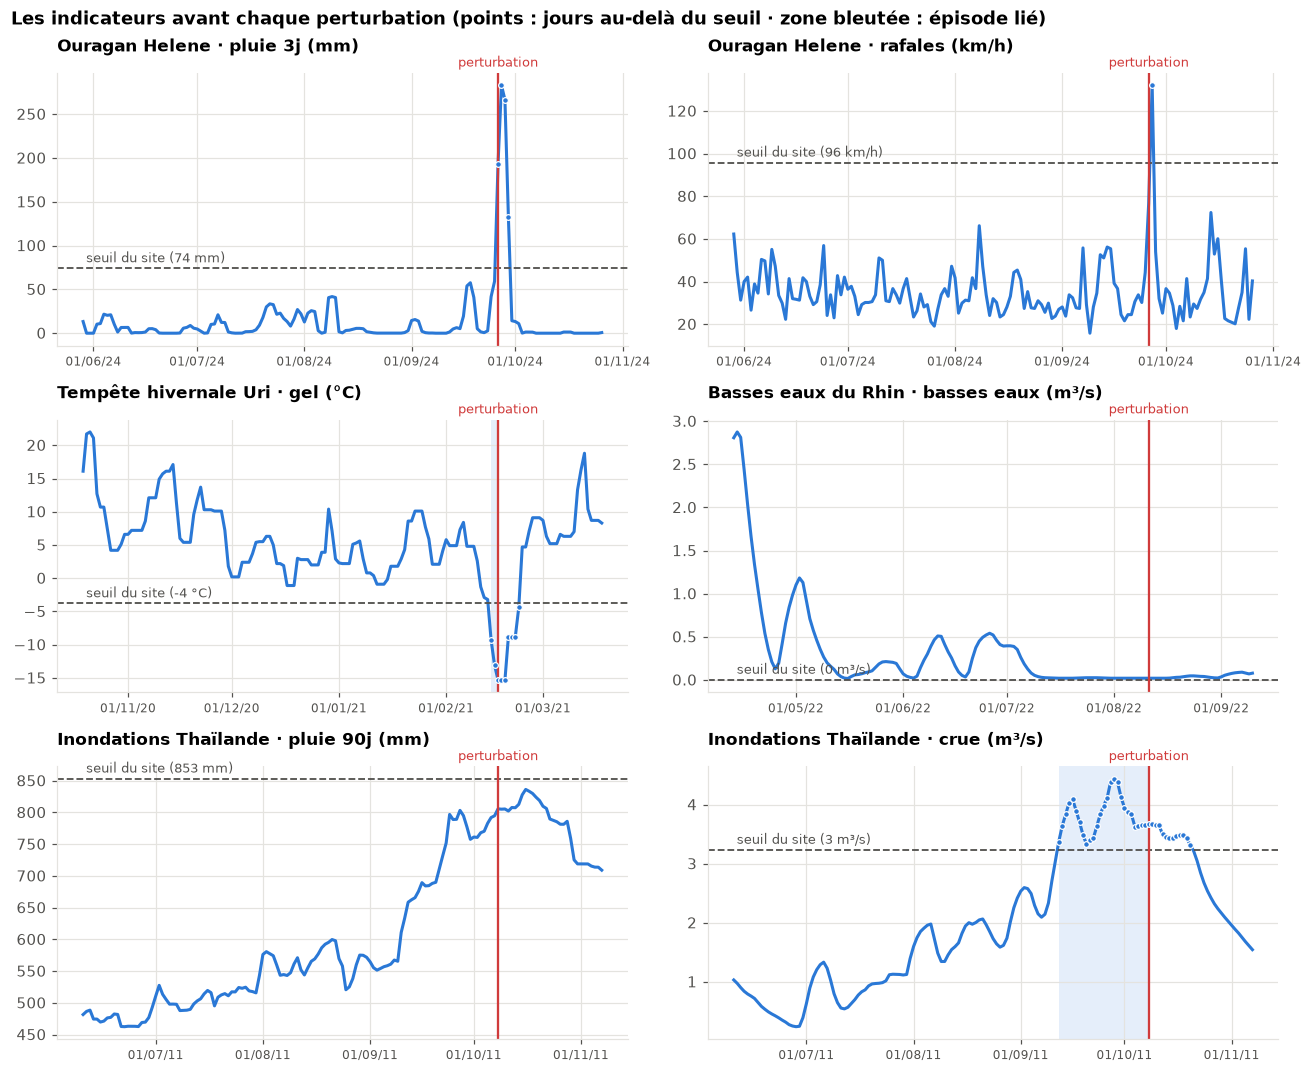

In [13]:
paires = [(c, nom) for c in CAS.itertuples() for nom in c.indicateurs]
ncol = 2
nlig = int(np.ceil(len(paires) / ncol))
fig, axes = plt.subplots(nlig, ncol, figsize=(12, 3.3 * nlig), squeeze=False)

for ax, (c, nom) in zip(axes.flat, paires):
    ind_t = next(i for i in INDICATEURS.itertuples() if i.indicateur == nom)
    exclure = c.date_perturbation.year if c.date_perturbation <= pd.Timestamp(FIN_CALIBRATION) else None
    s = seuil(c.site, ind_t, exclure_annee=exclure)
    fen = donnees[(donnees["site"] == c.site)
                  & (donnees["date"] >= c.date_perturbation - pd.Timedelta(days=FENETRE_AVANT))
                  & (donnees["date"] <= c.date_perturbation + pd.Timedelta(days=FENETRE_APRES))]
    ax.plot(fen["date"], fen[ind_t.colonne], color=BLEU, lw=2)
    if pd.notna(s):
        ax.axhline(s, color=ENCRE_2, lw=1.2, ls="--")
        ax.annotate(f"seuil du site ({s:.0f} {ind_t.unite})", xy=(fen["date"].iloc[0], s),
                    xytext=(2, 4), textcoords="offset points", color=ENCRE_2, fontsize=8.5)
        alerte = depasse(fen[ind_t.colonne], s, ind_t).fillna(False)
        ax.scatter(fen.loc[alerte, "date"], fen.loc[alerte, ind_t.colonne], s=14, color=BLEU,
                   edgecolor="white", linewidth=0.8, zorder=3)
        debut_ep = episode_lie(fen, ind_t, s, c.date_perturbation)
        if pd.notna(debut_ep):
            ax.axvspan(debut_ep, max(debut_ep, c.date_perturbation), color=BLEU, alpha=0.12, lw=0)
    ax.axvline(c.date_perturbation, color=ROUGE_CRITIQUE, lw=1.5)
    ax.annotate("perturbation", xy=(c.date_perturbation, 1), xycoords=("data", "axes fraction"),
                xytext=(0, 2), textcoords="offset points", ha="center", va="bottom",
                color=ROUGE_CRITIQUE, fontsize=8.5, annotation_clip=False)
    ax.set_title(f"{c.cas} · {nom.replace('_', ' ')} ({ind_t.unite})", loc="left", pad=14)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
    ax.tick_params(axis="x", labelsize=8)

for ax in axes.flat[len(paires):]:
    ax.set_visible(False)
fig.suptitle("Les indicateurs avant chaque perturbation (points : jours au-delà du seuil · zone bleutée : épisode lié)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

## 7. Le bruit : combien d'alertes par an ?

Un indicateur qui détecte les crises mais alerte toutes les semaines est inutilisable. On compte les **épisodes d'alerte** (jours consécutifs au-delà du seuil regroupés en un seul épisode) par site et par an, sur toute la période.

Par construction, un seuil au quantile 99 % est franchi environ 3,65 jours par an. Les épisodes sont moins nombreux quand les jours d'alerte se suivent, ce qui est le cas des indicateurs cumulés.

In [14]:
def compter_episodes(drapeaux):
    d = drapeaux.astype(bool).to_numpy()
    return int(np.sum(d[1:] & ~d[:-1]) + (d[0] if len(d) else 0))


nb_annees = (donnees["date"].max() - donnees["date"].min()).days / 365.25
EPISODES = pd.DataFrame({
    ind: donnees.groupby("site")[f"alerte_{ind}"].apply(compter_episodes) / nb_annees
    for ind in INDICATEURS["indicateur"]
}).loc[SITES["site"]]
# un indicateur sans seuil (ex. pas de rivière) n'a pas d'alerte : on l'affiche vide plutôt que 0
for (site, ind), s in SEUIL.items():
    if np.isnan(s):
        EPISODES.loc[site, ind] = np.nan
EPISODES["total_par_site"] = EPISODES.sum(axis=1, min_count=1)
EPISODES.round(1)

,pluie_3j,pluie_90j,rafales,neige,chaleur,gel,crue,basses_eaux,total_par_site
site,,,,,,,,,
Spruce Pine,1.7,0.2,3.2,2.6,2.3,0.8,0.7,0.5,12.1
Austin,1.6,0.2,2.9,0.4,1.7,1.1,0.2,1.1,9.2
Savannah,1.8,0.2,2.9,0.2,2.4,1.1,0.2,0.5,9.2
Kaub (Rhin),2.1,1.1,2.4,1.5,2.4,0.5,0.6,0.0,10.6
Rotterdam,2.9,0.4,3.5,3.6,2.5,0.4,0.8,1.0,15.0
Hambourg,2.8,0.5,2.3,3.4,2.0,0.6,1.0,1.0,13.7
Ayutthaya,2.5,1.0,2.9,0.0,1.7,0.6,0.5,0.0,9.1
Kaohsiung,1.4,0.4,2.7,0.0,2.7,0.9,0.8,0.7,9.6
Shanghai,1.7,0.3,2.7,0.2,2.7,1.1,NaN,NaN,8.8


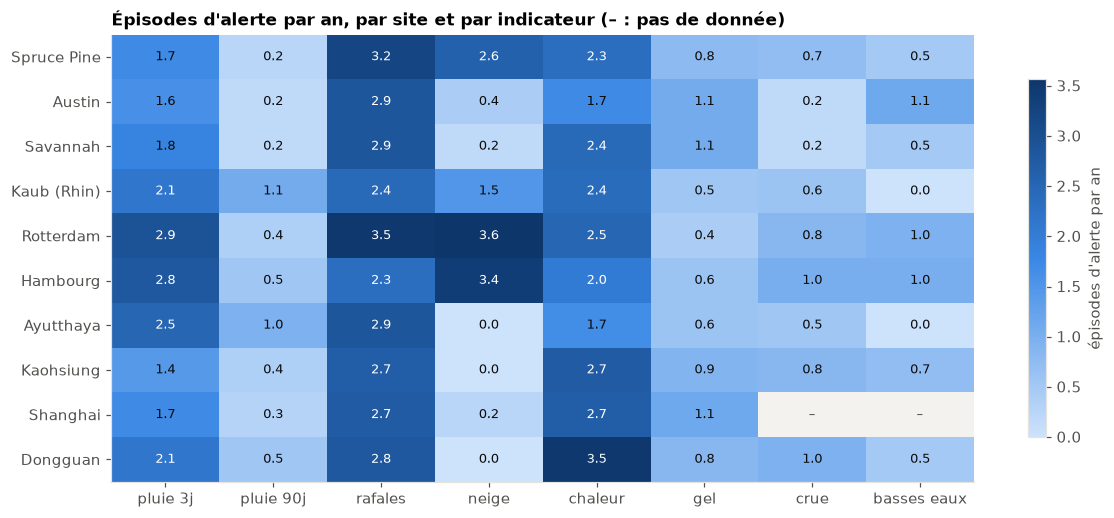

Total, tous sites confondus : 108 épisodes d'alerte météo par an.


In [15]:
vals = EPISODES.drop(columns="total_par_site")
fig, ax = plt.subplots(figsize=(11, 4.8))
masque = np.ma.masked_invalid(vals.to_numpy())
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("bleu", ["#cde2fb", "#3987e5", "#0d366b"])
cmap.set_bad("#f3f2ef")
im = ax.imshow(masque, cmap=cmap, aspect="auto")
ax.set_xticks(range(vals.shape[1]), [c.replace("_", " ") for c in vals.columns], rotation=0)
ax.set_yticks(range(vals.shape[0]), vals.index)
ax.grid(False)
seuil_texte = np.nanmax(masque) * 0.55 if masque.count() else 0
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8.5,
                    color="white" if v > seuil_texte else ENCRE)
        else:
            ax.text(j, i, "–", ha="center", va="center", fontsize=8.5, color=ENCRE_2)
fig.colorbar(im, ax=ax, shrink=0.8, label="épisodes d'alerte par an")
ax.set_title("Épisodes d'alerte par an, par site et par indicateur (– : pas de donnée)", loc="left")
fig.tight_layout()
plt.show()

print(f"Total, tous sites confondus : {EPISODES['total_par_site'].sum():.0f} épisodes d'alerte météo par an.")

**À lire** : le total tous sites confondus est le nombre d'alertes qu'un acheteur recevrait chaque année si la météo seule déclenchait une alerte critique. S'il dépasse ce qu'une équipe peut traiter, la météo doit servir de **risque de fond**, qui fait monter le score d'un fournisseur, et non d'alerte critique à elle seule. C'est le graphe (le site est-il critique pour nous ?) et les stocks (combien de jours de couverture ?) qui décident si l'alerte remonte.

## 8. La vraie anticipation : que prévoyaient les modèles avant Helene ?

L'API *Previous Runs* donne, pour chaque heure, la prévision émise 1 à 7 jours avant (`precipitation_previous_day1` … `_day7`). On compare la pluie prévue sur le 25-27 septembre 2024 à Spruce Pine selon l'avance de la prévision, au seuil du site.

L'avance est approximative : une prévision « J-3 » est émise environ trois jours avant chaque heure de la fenêtre.

,avance,pluie_prevue_3j_mm,depasse_seuil
0,J-0 (analyse),253.1,True
1,J-1,380.1,True
2,J-2,176.8,True
3,J-3,137.5,True
4,J-4,143.2,True
5,J-5,32.0,False
6,J-6,17.6,False
7,J-7,5.7,False


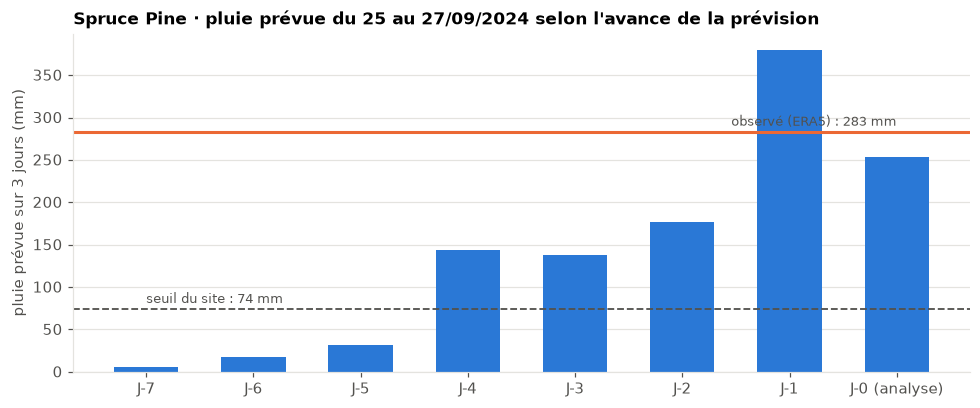

Prévisions qui dépassaient le seuil du site : J-1, J-2, J-3, J-4 (avance maximale testée : J-7).


In [16]:
SITE_PREV, DEBUT_EV, FIN_EV = "Spruce Pine", "2024-09-25", "2024-09-27"
site_prev = SITES.set_index("site").loc[SITE_PREV]
variables_prev = ["precipitation"] + [f"precipitation_previous_day{n}" for n in range(1, 8)]
params = dict(latitude=site_prev.lat, longitude=site_prev.lon, start_date="2024-09-20", end_date="2024-09-30",
              hourly=",".join(variables_prev), timezone="auto")

try:
    prev = vers_dataframe(appel_api(URL_PREVIOUS, params), bloc="hourly")
    fenetre = prev[(prev["date"] >= DEBUT_EV) & (prev["date"] < pd.Timestamp(FIN_EV) + pd.Timedelta(days=1))]
    cumul = fenetre[variables_prev].sum(min_count=1)
    PREVISIONS = pd.DataFrame({
        "avance": ["J-0 (analyse)"] + [f"J-{n}" for n in range(1, 8)],
        "pluie_prevue_3j_mm": cumul.values,
    })
    seuil_sp = SEUIL[(SITE_PREV, "pluie_3j")]
    observe = donnees[(donnees["site"] == SITE_PREV) & (donnees["date"] == FIN_EV)]["pluie_3j"].iloc[0]
    PREVISIONS["depasse_seuil"] = PREVISIONS["pluie_prevue_3j_mm"] > seuil_sp
    display(PREVISIONS.round(1))

    plot = PREVISIONS.iloc[::-1].dropna()
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(plot["avance"], plot["pluie_prevue_3j_mm"], color=BLEU, width=0.6, zorder=2)
    ax.grid(axis="x", visible=False)
    ax.axhline(seuil_sp, color=ENCRE_2, ls="--", lw=1.2)
    ax.annotate(f"seuil du site : {seuil_sp:.0f} mm", xy=(0, seuil_sp), xytext=(0, 4),
                textcoords="offset points", color=ENCRE_2, fontsize=8.5)
    ax.axhline(observe, color=ORANGE, lw=2)
    ax.annotate(f"observé (ERA5) : {observe:.0f} mm", xy=(len(plot) - 1, observe), xytext=(0, 4),
                textcoords="offset points", ha="right", color=ENCRE_2, fontsize=8.5)
    ax.set_ylabel("pluie prévue sur 3 jours (mm)")
    ax.set_title(f"{SITE_PREV} · pluie prévue du 25 au 27/09/2024 selon l'avance de la prévision", loc="left")
    fig.tight_layout()
    plt.show()

    alerte_prev = PREVISIONS.loc[PREVISIONS["depasse_seuil"] & (PREVISIONS["avance"] != "J-0 (analyse)"), "avance"]
    if len(alerte_prev):
        print("Prévisions qui dépassaient le seuil du site : " + ", ".join(alerte_prev) + " (avance maximale testée : J-7).")
    else:
        print("Aucune prévision de J-1 à J-7 ne dépassait le seuil du site.")
except RuntimeError as erreur:
    print(f"Prévisions archivées indisponibles pour cette requête : {erreur}")

## 9. Mode live : alertes sur les 16 prochains jours

On applique les mêmes seuils aux prévisions du jour. `past_days=92` récupère aussi les 92 derniers jours pour calculer les cumuls sur 90 jours.

In [17]:
previsions_live = []
for site in SITES.itertuples():
    p = dict(latitude=site.lat, longitude=site.lon, daily=",".join(VARIABLES_JOUR),
             past_days=92, forecast_days=16, timezone="auto")
    df = vers_dataframe(appel_api(URL_FORECAST, p))
    df.insert(0, "site", site.site)
    try:
        q = dict(latitude=site.lat, longitude=site.lon, daily="river_discharge", past_days=92, forecast_days=16)
        df = df.merge(vers_dataframe(appel_api(URL_FLOOD, q))[["date", "river_discharge"]], on="date", how="left")
    except RuntimeError:
        df["river_discharge"] = np.nan
    previsions_live.append(df)

live = ajouter_indicateurs(pd.concat(previsions_live, ignore_index=True))
live = live[live["date"] >= pd.Timestamp(date.today())]

alertes = []
for ind in INDICATEURS.itertuples():
    for site, bloc in live.groupby("site"):
        s = SEUIL[(site, ind.indicateur)]
        if np.isnan(s):
            continue
        touche = bloc[depasse(bloc[ind.colonne], s, ind).fillna(False)]
        for r in touche.itertuples():
            alertes.append(dict(site=site, date=r.date.date(), indicateur=ind.indicateur,
                                valeur=round(getattr(r, ind.colonne), 1), seuil=round(s, 1),
                                unite=ind.unite, risque=ind.risque))

ALERTES_LIVE = pd.DataFrame(alertes, columns=["site", "date", "indicateur", "valeur", "seuil", "unite", "risque"])
if ALERTES_LIVE.empty:
    print(f"Aucune alerte météo prévue d'ici le {(date.today() + timedelta(days=15)):%d/%m/%Y}.")
else:
    display(ALERTES_LIVE.sort_values(["date", "site"]))

,site,date,indicateur,valeur,seuil,unite,risque
1,Shanghai,2026-11-09,rafales,77.8,76.2,km/h,"Arrêt des ports et des grues, dégâts"
0,Rotterdam,2026-11-18,rafales,94.0,93.5,km/h,"Arrêt des ports et des grues, dégâts"
2,Spruce Pine,2026-11-20,basses_eaux,3.8,3.8,m³/s,Navigation fluviale limitée
3,Spruce Pine,2026-11-21,basses_eaux,3.8,3.8,m³/s,Navigation fluviale limitée
4,Spruce Pine,2026-11-22,basses_eaux,3.8,3.8,m³/s,Navigation fluviale limitée


## 10. Quelles informations sont utiles ?

Synthèse automatique par indicateur :

- **cas détectés** : perturbations réelles où l'indicateur a dépassé son seuil avant la date de l'impact ;
- **épisodes par an et par site** : le bruit moyen ;
- **sites sans donnée** : là où l'indicateur ne peut pas servir.

In [18]:
synthese = INDICATEURS[["indicateur", "risque"]].set_index("indicateur")
testes = VALIDATION.groupby("indicateur")["alerte_avant_perturbation"]
synthese["cas_testes"] = testes.size()
synthese["cas_detectes"] = testes.sum()
synthese["avance_mediane_j"] = VALIDATION[VALIDATION["alerte_avant_perturbation"]].groupby("indicateur")["jours_avance"].median()
synthese["episodes_par_an_et_site"] = EPISODES.drop(columns="total_par_site").mean().round(1)
synthese["sites_sans_donnee"] = EPISODES.drop(columns="total_par_site").isna().sum()
synthese = synthese.fillna({"cas_testes": 0, "cas_detectes": 0}).astype({"cas_testes": int, "cas_detectes": int})
synthese.to_csv(OUT_DIR / "meteo_synthese_indicateurs.csv")
synthese

,risque,cas_testes,cas_detectes,avance_mediane_j,episodes_par_an_et_site,sites_sans_donnee
indicateur,,,,,,
pluie_3j,"Crue éclair, routes et voies ferrées coupées",1,0,NaN,2.1,0
pluie_90j,"Inondation lente, zones industrielles noyées",1,0,NaN,0.5,0
rafales,"Arrêt des ports et des grues, dégâts",1,0,NaN,2.8,0
neige,Routes et rail bloqués,0,0,NaN,1.2,0
chaleur,"Canicule : coupures électriques, rendement",0,0,NaN,2.4,0
gel,"Gel : coupures électriques, installations gelées",1,1,2.0,0.8,0
crue,Crue de rivière,1,1,26.0,0.6,1
basses_eaux,Navigation fluviale limitée,1,0,NaN,0.6,1


**Comment conclure à partir de ce tableau**

- Un indicateur qui **détecte ses cas** avec un **bruit modéré** est à garder tel quel.
- Un indicateur qui détecte mais **alerte trop souvent** est à garder avec un seuil plus strict (quantile 99,5 %) ou en le combinant à un autre (pluie **et** débit, par exemple).
- Un indicateur **jamais testé** (neige, chaleur ici) n'est pas inutile : il faut lui trouver une perturbation réelle de référence avant de le présenter comme fiable.
- Un indicateur **sans donnée** sur beaucoup de sites (débit sur les sites côtiers) ne s'applique qu'aux sites qui dépendent d'une rivière.

**Limites à citer en soutenance**

- ERA5 est une grille de ~25 km : elle **lisse les extrêmes locaux**, surtout les rafales et les orages. Les valeurs absolues sont sous-estimées, mais comme les seuils viennent des mêmes données, la comparaison reste cohérente.
- Le débit GloFAS prend la **plus grande rivière dans un rayon de 5 km** : vérifier sur une carte que c'est bien la bonne.
- Quatre cas ne font pas une statistique : ils montrent que la méthode **peut** marcher, pas qu'elle est fiable en général.
- Les prévisions archivées ne remontent qu'à **janvier 2024** pour la plupart des modèles : seul Helene peut être testé en vraie prévision.

## 11. Exports pour la suite du projet

In [19]:
colonnes_export = (["site", "date"] + list(dict.fromkeys(INDICATEURS["colonne"]))
                   + cols_alerte + ["score_meteo", "alerte_meteo"])
donnees[colonnes_export].to_csv(OUT_DIR / "meteo_indicateurs_journaliers.csv", index=False)
SEUILS.to_csv(OUT_DIR / "meteo_seuils_par_site.csv", index=False)
VALIDATION.to_csv(OUT_DIR / "meteo_validation_cas.csv", index=False)
EPISODES.to_csv(OUT_DIR / "meteo_episodes_par_an.csv")
ALERTES_LIVE.to_csv(OUT_DIR / "meteo_alertes_16_jours.csv", index=False)

for f in sorted(OUT_DIR.glob("*.csv")):
    print(f"{f.name:<40} {f.stat().st_size / 1e6:6.2f} Mo")

meteo_alertes_16_jours.csv                 0.00 Mo
meteo_brut.csv                             3.75 Mo
meteo_episodes_par_an.csv                  0.00 Mo
meteo_indicateurs_journaliers.csv          9.35 Mo
meteo_seuils_par_site.csv                  0.00 Mo
meteo_synthese_indicateurs.csv             0.00 Mo
meteo_validation_cas.csv                   0.00 Mo


`meteo_indicateurs_journaliers.csv` est la table à brancher sur le moteur de scoring : une ligne par site et par jour, avec le `score_meteo` (0 à 1) qui alimente le **risque de fond** de chaque nœud du graphe fournisseurs.

**Sources** : [Open-Meteo](https://open-meteo.com/) (données sous licence CC BY 4.0, à citer) · Hersbach et al., *ERA5 hourly data*, Copernicus · GloFAS, Copernicus Emergency Management Service.